# Cold–warm: gradient & warm/cold-50% fraction plots

_Run `cw_calculations.ipynb` first. 20% ranges removed; dataframe-prep cells included so boxplots work._


In [1]:
# Load Packages
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.transforms as transforms
import cartopy.crs as ccrs
import calendar, os, re
from matplotlib.lines import Line2D
import seaborn as sns
import pandas as pd
import matplotlib.gridspec as gridspec
from scipy.stats import norm, scoreatpercentile
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

%matplotlib inline


In [2]:
import sys, os
_p = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_p, 'functions.py')):
        sys.path.insert(0, _p); break
    _p = os.path.dirname(_p)
from functions import *


In [3]:
# Load variables computed in cw_calculations.ipynb
load_state(globals())


[load_state] loaded 215 variables from /Users/isabelaconde/Documents/GitHub/JRA55-do_ctrl_ERA5-forcings/processed_data/state.pkl
[load_state] available: DA_all, In, Out, STATE_DIR, STATE_FILE, all_trend_percentiles, ax, basin_cmip, basin_era5, basin_jra55, basin_noaa, basin_omip ...


{'In': ['',
  "# Load Packages\nimport numpy as np\nimport xarray as xr\nimport matplotlib\nimport matplotlib.pyplot as plt\nimport matplotlib.transforms as transforms\nimport cartopy.crs as ccrs\nimport calendar, os, re, datetime\nfrom datetime import datetime as _dt\nfrom pathlib import Path\nfrom matplotlib.lines import Line2D\nimport seaborn as sns\nimport pandas as pd\nimport matplotlib.gridspec as gridspec\nfrom scipy.stats import norm, scoreatpercentile\nfrom mpl_toolkits.axes_grid1 import make_axes_locatable\nimport matplotlib.patches as patches\nfrom matplotlib.gridspec import GridSpec\nfrom xhistogram.xarray import histogram\n\nget_ipython().run_line_magic('matplotlib', 'inline')",
  "import sys, os\n_p = os.getcwd()\nfor _ in range(6):\n    if os.path.exists(os.path.join(_p, 'functions.py')):\n        sys.path.insert(0, _p); break\n    _p = os.path.dirname(_p)\nfrom functions import *  # shared helper functions",
  "def quantiles_xhist(data):\n    hist_T = data.sel(lon = sli

# cold warm temp grad

In [4]:
cw_omip = {}
for i, da in enumerate(mod_labs):
    cw_omip[da]=percentiles_omip_trend[da].sel(area = slice(0.5,1)).mean(dim = 'area') - percentiles_omip_trend[da].sel(area = slice(0,0.5)).mean(dim = 'area')
    # print('cw calculated for ' + mod_labs[i])
print('omip cualculated')
# cw_omip
cw_omip 

cw_cmip = DA_all.sel(area = slice(0.5,1)).mean(dim = 'area') - DA_all.sel(area = slice(0,0.5)).mean(dim = 'area')
print('cmip cw calculated')

cw_noaa = noaa_sst_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - noaa_sst_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
print('noaa cw calculated')

cw_jra55 = control_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - control_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_era5 = era5_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - era5_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
# cw_perturb = perturb_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
# cw_perturb_uas = perturb_percent_era5_uas_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_era5_uas_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_uas_vas = perturb_percent_era5_uas_vas_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_era5_uas_vas_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_huss_tas = perturb_percent_era5_huss_tas_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_era5_huss_tas_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_rsds_rlds = perturb_percent_era5_rsds_rlds_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_era5_rsds_rlds_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_winds = perturb_percent_era5_winds.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_era5_winds.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_all = perturb_percent_all_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_all_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_cm2 = cm2_percent_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - cm2_percent_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
cw_perturb_winds_mean_trend = perturb_percent_winds_mean_trend.sel(area = slice(0.5,1)).mean(dim = 'area') - perturb_percent_winds_mean_trend.sel(area = slice(0,0.5)).mean(dim = 'area')
print('perturbation cw calculated')

omip cualculated
cmip cw calculated
noaa cw calculated
perturbation cw calculated


In [5]:
# omip_models
# cw_omip
lo = cw_cmip.quantile(0.1, dim="run")
hi = cw_cmip.quantile(0.9, dim="run")

cw_cmip_trim = cw_cmip #.where((cw_cmip >= lo) & (cw_cmip <= hi), drop=True)

df_cw_cmip = (cw_cmip_trim*10*12).to_dataframe(name="value").reset_index()
df_cw_cmip["group"] = "CMIP"


vals = [float(v.values*10*12) for v in cw_omip.values()]   
df_omip = pd.DataFrame({"value": vals})
df_omip["group"] = "OMIP"

df_all = pd.concat([df_cw_cmip[["value","group"]], df_omip], ignore_index=True)
# df_all


# df_mean_cmip = (cw_cmip*10*12).mean(dim='run').to_dataframe('values').reset_index()
# df_mean_omip = np.mean(vals*10*12).to_dataframe('values').reset_index()
# df_all = pd.concat([df_mean_cmip[["value","group"]], df_mean_omip], ignore_index=True)

# means (already scaled)
mean_cmip = (cw_cmip * 10 * 12).mean("run").item()
mean_omip = np.mean(vals)  # vals already scaled in your list comprehension

df_mean_cmip = pd.DataFrame({"value": [mean_cmip], "group": ["CMIP"]})
df_mean_omip = pd.DataFrame({"value": [mean_omip], "group": ["OMIP"]})

df_means = pd.concat([df_mean_cmip, df_mean_omip], ignore_index=True)


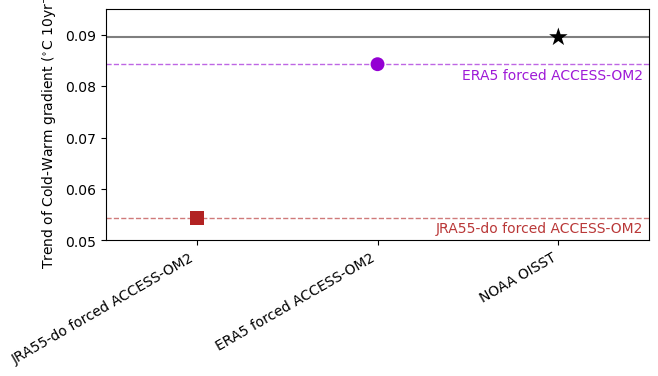

In [9]:

sources = ['JRA55-do forced ACCESS-OM2','ERA5 forced ACCESS-OM2','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = [ 'firebrick','darkviolet', 'cyan','b', 'violet', 'limegreen', 'red', 'k']

obs_perturb_df = pd.DataFrame({
    'Source': ['JRA55-do forced ACCESS-OM2','ERA5 forced ACCESS-OM2','NOAA OISST'],
    'values': np.array([cw_jra55.values, cw_era5.values, cw_noaa.values])*10*12
})

obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})
obs_perturb_df["group"] = obs_perturb_df["Source"]

order = list(obs_perturb_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_df["group"].eq("NOAA OISST")
import matplotlib.transforms as transforms

markers = [ 's','o',  '*']  # last one is NOAA
colors  = [ 'firebrick','darkviolet', 'k']

fig, ax = plt.subplots(figsize=(7, 3))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

# sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
# sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})

# NOAA reference line
ax.axhline(y=float(cw_noaa.values) * 10 * 12, color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})  # if needed
obs_perturb_df["group"] = obs_perturb_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5
    )

# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5 forced ACCESS-OM2", "JRA55-do forced ACCESS-OM2"]:
    if (obs_perturb_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=30, ha="right")
plt.ylim(0.05, 0.095)


plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_om2.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_54178/3598102527.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_54178/3598102527.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})


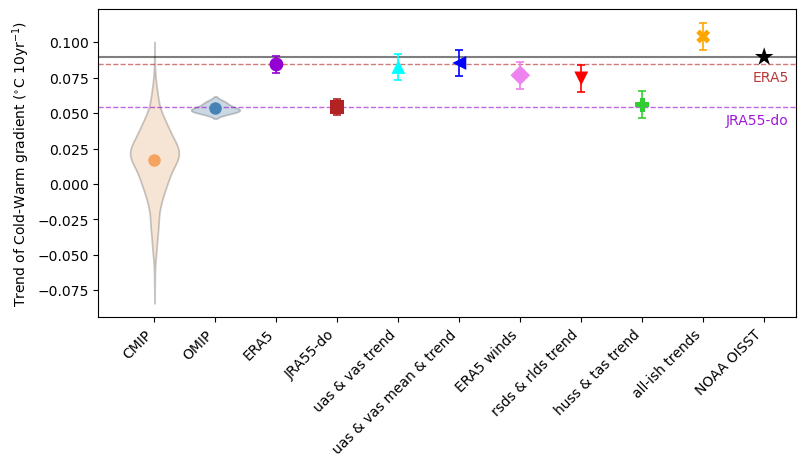

In [10]:


err = {
    "CMIP": np.nan,
    "OMIP": np.nan,
    "JRA55-do": 0.01115278288664186/1.96,         
    "ERA5": 0.011415798450934676/1.96,
    "uas & vas trend": 0.018202355388919844/1.96,
    "uas & vas mean & trend": 0.018152164284731393/1.96,
    "ERA5 winds": 0.018500552008223252/1.96,
    "rsds & rlds trend": 0.018173839415532484/1.96,
    "huss & tas trend": 0.018219742788782828/1.96,
    "all-ish trends": 0.0182/1.96,              
    "NOAA OISST": np.nan,                     
}

obs_perturb_df = pd.DataFrame({
    'Source': ['ERA5','JRA55-do','uas & vas trend','uas & vas mean & trend','ERA5 winds', 'rsds & rlds trend','huss & tas trend','all-ish trends','NOAA OISST'],
    'values': np.array([cw_era5.values,cw_jra55.values,cw_perturb_uas_vas.values,cw_perturb_winds_mean_trend.values,cw_perturb_winds.values, cw_perturb_rsds_rlds.values,
                        cw_perturb_huss_tas.values, cw_perturb_all.values, cw_noaa.values])*10*12
})

# # make sure we’re using the same x-order as the plot
# order2 = order if "order" in globals() and order is not None else list(obs_perturb_df["group"].unique())
# xpos = {g: i for i, g in enumerate(order2)}


obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})
obs_perturb_df["group"] = obs_perturb_df["Source"]

order = list(obs_perturb_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_df["group"].eq("NOAA OISST")
import matplotlib.transforms as transforms

markers = ['o', 's', '^',  '<','D','v', 'P', 'X', '*']  # last one is NOAA
colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen', 'orange',  'red', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})



# NOAA reference line
ax.axhline(y=float(cw_noaa.values) * 10 * 12, color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})  # if needed
obs_perturb_df["group"] = obs_perturb_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5, jitter =False
    )
xy = {}

for coll in ax.collections:
    offs = getattr(coll, "get_offsets", None)
    if offs is None:
        continue

    offs = coll.get_offsets()
    if len(offs) == 0:
        continue

    for xpt, ypt in np.asarray(offs):
        xy[float(ypt)] = float(xpt)

# draw error bars at the x-position of the matching point (by y-value)
for s in obs_perturb_df["group"]:
    if s not in err:
        continue

    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == s, "value"].iloc[0])
    e = float(err[s])

    # find the plotted x coordinate for this point
    x = xy.get(y, None)
    if x is None:
        # fallback: category center (should rarely happen)
        x = order2.index(s)

    ax.errorbar(
        x, y, yerr=e,
        fmt="none",
        ecolor=color_map.get(s, "k"),
        elinewidth=1.2,
        capsize=3,
        capthick=1.2,
        zorder=20
    )
# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5", "JRA55-do"]:
    if (obs_perturb_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=45, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_54178/1748109705.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
/var/folders/3m/hb6030nd3ml4fk_t3lq08f4w0000gn/T/ipykernel_54178/1748109705.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})


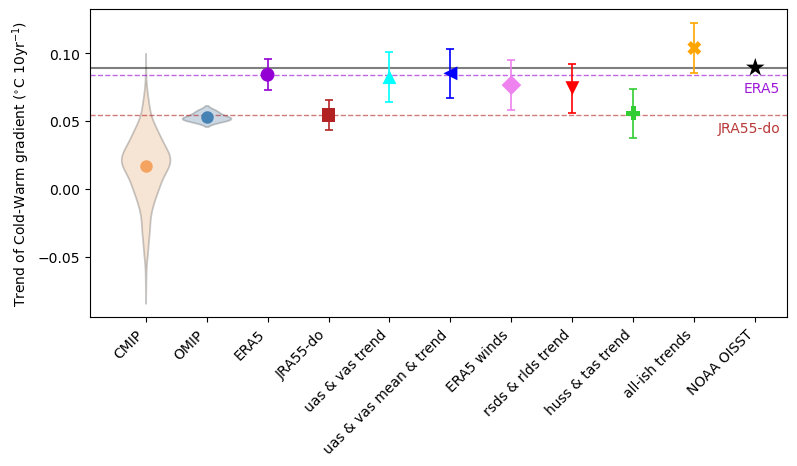

In [11]:


err = {
    "CMIP": np.nan,
    "OMIP": np.nan,
    "JRA55-do": 0.01115278288664186,         
    "ERA5": 0.011415798450934676,
    "uas & vas trend": 0.018202355388919844,
    "uas & vas mean & trend": 0.018152164284731393,
    "ERA5 winds": 0.018500552008223252,
    "rsds & rlds trend": 0.018173839415532484,
    "huss & tas trend": 0.018219742788782828,
    "all-ish trends": 0.0182,              
    "NOAA OISST": np.nan,                     
}

obs_perturb_df = pd.DataFrame({
    'Source': ['ERA5','JRA55-do','uas & vas trend','uas & vas mean & trend','ERA5 winds', 'rsds & rlds trend','huss & tas trend','all-ish trends','NOAA OISST'],
    'values': np.array([cw_era5.values,cw_jra55.values,cw_perturb_uas_vas.values,cw_perturb_winds_mean_trend.values,cw_perturb_winds.values, cw_perturb_rsds_rlds.values,
                        cw_perturb_huss_tas.values, cw_perturb_all.values, cw_noaa.values])*10*12
})

# # make sure we’re using the same x-order as the plot
# order2 = order if "order" in globals() and order is not None else list(obs_perturb_df["group"].unique())
# xpos = {g: i for i, g in enumerate(order2)}


obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})
obs_perturb_df["group"] = obs_perturb_df["Source"]

order = list(obs_perturb_df["group"].unique())
pal = dict(zip(order, colors[:len(order)]))

noaa = obs_perturb_df["group"].eq("NOAA OISST")
import matplotlib.transforms as transforms

markers = ['o', 's', '^',  '<','D','v', 'P', 'X', '*']  # last one is NOAA
colors  = ['darkviolet', 'firebrick', 'cyan', 'b', 'violet','r', 'limegreen', 'orange',  'red', 'k']

fig, ax = plt.subplots(figsize=(9, 4))
trans = transforms.blended_transform_factory(ax.transAxes, ax.transData)

sns.violinplot(data=df_all, x="group", y="value", inner=None, ax=ax, palette={"CMIP": "sandybrown", "OMIP": "steelblue"}, alpha=0.3 )
sns.stripplot(data=df_means, x="group", y="value", ax=ax, marker="o", size=9, palette={"CMIP": "sandybrown", "OMIP": "steelblue"})



# NOAA reference line
ax.axhline(y=float(cw_noaa.values) * 10 * 12, color='k', linestyle='-', linewidth=1.5, alpha=0.5, label='_nolegend_')

# --- obs/perturb points: one per Source, with per-source marker (NOAA gets '*') ---
obs_perturb_df = obs_perturb_df.rename(columns={"values": "value"})  # if needed
obs_perturb_df["group"] = obs_perturb_df["Source"]

# ensure consistent x ordering for these points
srcs = list(obs_perturb_df["group"].unique())
order2 = order if "order" in globals() and order is not None else srcs

# map source -> (marker, color) with NOAA last
non_noaa_sources = [s for s in order2 if s in srcs and s != "NOAA OISST"]
noaa_source = "NOAA OISST" if "NOAA OISST" in srcs else None

marker_map = {}
color_map  = {}

# assign markers/colors to non-NOAA (cycled if needed)
for i, s in enumerate(non_noaa_sources):
    marker_map[s] = markers[i % (len(markers) - 1)]   # exclude last ('*')
    color_map[s]  = colors[i % (len(colors) - 1)]     # exclude last ('k') if you want NOAA black

# NOAA marker + colour
if noaa_source is not None:
    marker_map[noaa_source] = markers[-1]   # '*'
    color_map[noaa_source]  = colors[-1]    # 'k'

# plot each source separately so we can control marker per point
for s in non_noaa_sources + ([noaa_source] if noaa_source is not None else []):
    if s is None:
        continue
    sub = obs_perturb_df.loc[obs_perturb_df["group"] == s]
    sns.stripplot(
        data=sub, x="group", y="value", ax=ax,
        order=order2,
        marker=marker_map[s],
        size=(14 if marker_map[s] == "*" else 10),
        color=color_map[s],
        edgecolor="none", linewidth=0.5, jitter =False
    )
xy = {}

for coll in ax.collections:
    offs = getattr(coll, "get_offsets", None)
    if offs is None:
        continue

    offs = coll.get_offsets()
    if len(offs) == 0:
        continue

    for xpt, ypt in np.asarray(offs):
        xy[float(ypt)] = float(xpt)

# draw error bars at the x-position of the matching point (by y-value)
for s in obs_perturb_df["group"]:
    if s not in err:
        continue

    y = float(obs_perturb_df.loc[obs_perturb_df["group"] == s, "value"].iloc[0])
    e = float(err[s])

    # find the plotted x coordinate for this point
    x = xy.get(y, None)
    if x is None:
        # fallback: category center (should rarely happen)
        x = order2.index(s)

    ax.errorbar(
        x, y, yerr=e,
        fmt="none",
        ecolor=color_map.get(s, "k"),
        elinewidth=1.2,
        capsize=3,
        capthick=1.2,
        zorder=20
    )
# ERA5 + JRA55-do line labels
dy = 0.02 * (ax.get_ylim()[1] - ax.get_ylim()[0])
for src in ["ERA5", "JRA55-do"]:
    if (obs_perturb_df["group"] == src).any() and src in pal:
        y = float(obs_perturb_df.loc[obs_perturb_df["group"] == src, "value"].iloc[0])
        ax.axhline(y=y, color=pal[src], linestyle="--", linewidth=1, alpha=0.6, label="_nolegend_")
        ax.text(0.99, y - dy, src, transform=trans, ha="right", va="top",
                color=pal[src], alpha=0.9)

plt.xlabel('')
plt.ylabel(r'Trend of Cold-Warm gradient ($^{\circ}$C 10yr$^{-1}$)')
plt.xticks(rotation=45, ha="right")

plt.show()
outpath = "/Users/isabelaconde/Desktop/cw_1982-2017.pdf"
fig.savefig(outpath, format="pdf", bbox_inches="tight")

# warmest 50%

In [12]:
# warmest 50% mean only
warm50_omip = {}
for da in mod_labs:
    warm50_omip[da] = percentiles_omip_trend[da].sel(area=slice(0.5, 1)).mean(dim="area")
print("omip calculated")

warm50_cmip = DA_all.sel(area=slice(0.5, 1)).mean(dim="area")
print("cmip calculated")

warm50_noaa = noaa_sst_trend.sel(area=slice(0.5, 1)).mean(dim="area")
print("noaa calculated")

warm50_jra55 = control_percent_trend.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_era5  = era5_percent_trend.sel(area=slice(0.5, 1)).mean(dim="area")

warm50_perturb_uas_vas   = perturb_percent_era5_uas_vas_trend.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_perturb_huss_tas  = perturb_percent_era5_huss_tas_trend.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_perturb_rsds_rlds = perturb_percent_era5_rsds_rlds_trend.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_perturb_winds     = perturb_percent_era5_winds.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_perturb_all       = perturb_percent_all_trend.sel(area=slice(0.5, 1)).mean(dim="area")
# warm50_cm2 = cm2_percent_trend.sel(area=slice(0.5, 1)).mean(dim="area")
warm50_perturb_winds_mean_trend = perturb_percent_winds_mean_trend.sel(area=slice(0.5, 1)).mean(dim="area")
print("perturbation calculated")


omip calculated
cmip calculated
noaa calculated
perturbation calculated


In [15]:
# warm50_* versions

lo = warm50_cmip.quantile(0.1, dim="run")
hi = warm50_cmip.quantile(0.9, dim="run")

warm50_cmip_trim = warm50_cmip.where((warm50_cmip >= lo) & (warm50_cmip <= hi), drop=True)

df_warm50_cmip = (warm50_cmip_trim * 10 * 12).to_dataframe(name="value").reset_index()
df_warm50_cmip["group"] = "CMIP"

vals = [float(v.values * 10 * 12) for v in warm50_omip.values()]
df_omip = pd.DataFrame({"value": vals})
df_omip["group"] = "OMIP"

df_all = pd.concat([df_warm50_cmip[["value", "group"]], df_omip], ignore_index=True)

# means (already scaled)
mean_cmip = (warm50_cmip * 10 * 12).mean("run").item()
mean_omip = np.mean(vals)

df_mean_cmip = pd.DataFrame({"value": [mean_cmip], "group": ["CMIP"]})
df_mean_omip = pd.DataFrame({"value": [mean_omip], "group": ["OMIP"]})

df_means = pd.concat([df_mean_cmip, df_mean_omip], ignore_index=True)


# coldest 50%

In [16]:
# coldest 50% mean only
cold50_omip = {}
for da in mod_labs:
    cold50_omip[da] = percentiles_omip_trend[da].sel(area=slice(0, 0.5)).mean(dim="area")
print("omip calculated")

cold50_cmip = DA_all.sel(area=slice(0, 0.5)).mean(dim="area")
print("cmip calculated")

cold50_noaa = noaa_sst_trend.sel(area=slice(0, 0.5)).mean(dim="area")
print("noaa calculated")

cold50_jra55 = control_percent_trend.sel(area=slice(0, 0.5)).mean(dim="area")
cold50_era5  = era5_percent_trend.sel(area=slice(0, 0.5)).mean(dim="area")

cold50_perturb_uas_vas   = perturb_percent_era5_uas_vas_trend.sel(area=slice(0, 0.5)).mean(dim="area")
cold50_perturb_huss_tas  = perturb_percent_era5_huss_tas_trend.sel(area=slice(0, 0.5)).mean(dim="area")
cold50_perturb_rsds_rlds = perturb_percent_era5_rsds_rlds_trend.sel(area=slice(0, 0.5)).mean(dim="area")
cold50_perturb_winds     = perturb_percent_era5_winds.sel(area=slice(0, 0.5)).mean(dim="area")
cold50_perturb_all       = perturb_percent_all_trend.sel(area=slice(0, 0.5)).mean(dim="area")
# cold50_cm2 = cm2_percent_trend.sel(area=slice(0, 0.5)).mean(dim="area")
cold_50_perturb_winds_mean_trend = perturb_percent_winds_mean_trend.sel(area=slice(0, 0.5)).mean(dim="area")
print("perturbation calculated")


omip calculated
cmip calculated
noaa calculated
perturbation calculated


In [17]:
# cold50_* versions

lo = cold50_cmip.quantile(0.1, dim="run")
hi = cold50_cmip.quantile(0.9, dim="run")

cold50_cmip_trim = cold50_cmip.where((cold50_cmip >= lo) & (cold50_cmip <= hi), drop=True)

df_cold50_cmip = (cold50_cmip_trim * 10 * 12).to_dataframe(name="value").reset_index()
df_cold50_cmip["group"] = "CMIP"

vals = [float(v.values * 10 * 12) for v in cold50_omip.values()]
df_omip = pd.DataFrame({"value": vals})
df_omip["group"] = "OMIP"

df_all = pd.concat([df_cold50_cmip[["value", "group"]], df_omip], ignore_index=True)

# means (already scaled)
mean_cmip = (cold50_cmip * 10 * 12).mean("run").item()
mean_omip = np.mean(vals)

df_mean_cmip = pd.DataFrame({"value": [mean_cmip], "group": ["CMIP"]})
df_mean_omip = pd.DataFrame({"value": [mean_omip], "group": ["OMIP"]})

df_means = pd.concat([df_mean_cmip, df_mean_omip], ignore_index=True)


# 2 var plots 
- 3x3 
    - cold 50 vs. warm 50 
    - cold 50 vs. cw 
    - warm 50 vs. cw

In [19]:
lo_cold = cold50_cmip.quantile(0.1, dim="run")
hi_cold = cold50_cmip.quantile(0.9, dim="run")

cold50_cmip_trim = cold50_cmip*10*12 #.where((cold50_cmip >= lo_cold) & (cold50_cmip <= hi_cold), drop=True)*10*12

lo_warm = warm50_cmip.quantile(0.1, dim="run")
hi_warm = warm50_cmip.quantile(0.9, dim="run")

warm50_cmip_trim = warm50_cmip*10*12 #warm50_cmip.where((warm50_cmip >= lo_warm) & (warm50_cmip <= hi_warm), drop=True)*10*12


lo_cw = cw_cmip.quantile(0.1, dim="run")
hi_cw = cw_cmip.quantile(0.9, dim="run")

cw_cmip_trim = cw_cmip*10*12 #cw_cmip.where((cw_cmip >= lo_cw) & (cw_cmip <= hi_cw), drop=True)*10*12

# lo = cw_cmip.quantile(0.1, dim="run")
# hi = cw_cmip.quantile(0.9, dim="run")

# cw_cmip_trim = cw_cmip.where((cw_cmip >= lo) & (cw_cmip <= hi), drop=True)

# df_cw_cmip = (cw_cmip_trim*10*12).to_dataframe(name="value").reset_index()
# df_cw_cmip["group"] = "CMIP"


# plt.plot(warm50_cmip_trim, cold50_cmip_trim

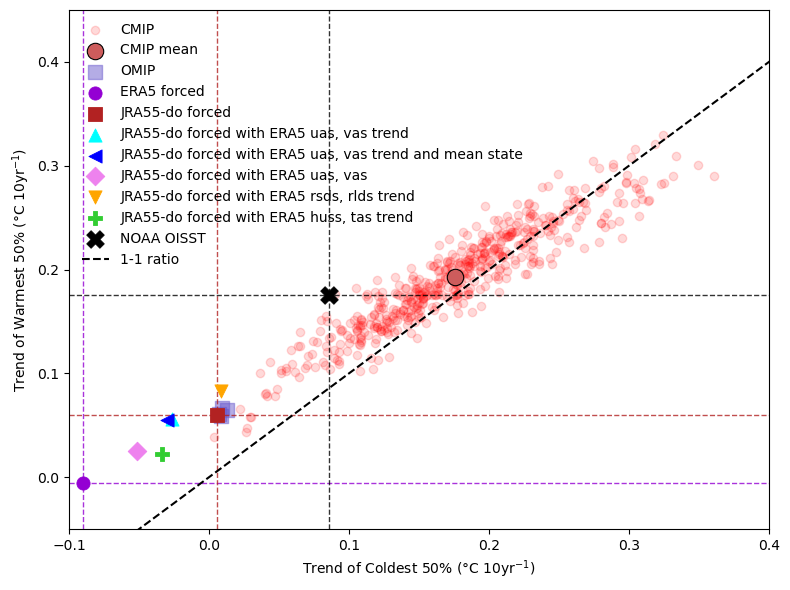

In [21]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# -------------------------
# Obs / perturb definitions
# -------------------------
sources = ['ERA5 forced','JRA55-do forced','JRA55-do forced with ERA5 uas, vas trend','JRA55-do forced with ERA5 uas, vas trend and mean state','JRA55-do forced with ERA5 uas, vas', 'JRA55-do forced with ERA5 rsds, rlds trend','JRA55-do forced with ERA5 huss, tas trend','NOAA OISST']
colors  = ['darkviolet', 'firebrick', 'cyan','b', 'violet', 'orange', 'limegreen', 'k']
cmap = dict(zip(sources, colors))

# warm50 obs (same order as sources)
warm50_obs_da = xr.DataArray(
    np.array([
        warm50_era5.values,
        warm50_jra55.values,
        warm50_perturb_uas_vas.values,
        warm50_perturb_winds_mean_trend.values,
        warm50_perturb_winds.values,
        warm50_perturb_rsds_rlds.values,
        warm50_perturb_huss_tas.values,
        # warm50_perturb_all.values,
        warm50_noaa.values
        ]) * 10 * 12,
    dims="source",
    coords={"source": sources},
    name="warm50_trend"
)

# cold50 obs (same order as sources)
cold50_obs_da = xr.DataArray(
    np.array([
        cold50_era5.values,
        cold50_jra55.values,
        cold50_perturb_uas_vas.values,
        cold_50_perturb_winds_mean_trend,
        cold50_perturb_winds.values,
        cold50_perturb_rsds_rlds.values,
        cold50_perturb_huss_tas.values,
        # cold50_perturb_all.values,
        cold50_noaa.values
        ]) * 10 * 12,
    dims="source",
    coords={"source": sources},
    name="cold50_trend"
)

markers = ['o', 's', '^',  '<','D','v', 'P', 'X', '*']  # last one is NOAA

# coldest 50% mean only
cold50_omip = {}
for da in mod_labs:
    cold50_omip[da] = percentiles_omip_trend[da].sel(area=slice(0, 0.5)).mean(dim="area")
vals_cold50 = [float(v.values * 10 * 12) for v in cold50_omip.values()]

warm50_omip = {}
for da in mod_labs:
    warm50_omip[da] = percentiles_omip_trend[da].sel(area=slice(0.5, 1)).mean(dim="area")

vals_warm50 = [float(v.values * 10 * 12) for v in warm50_omip.values()]
# vals

fig, ax = plt.subplots(figsize=(8, 6))

# CMIP cloud
ax.scatter(cold50_cmip_trim,warm50_cmip_trim, color='red', alpha=0.15, label='CMIP')

cmip_xmean = np.nanmean(warm50_cmip_trim)
cmip_ymean = np.nanmean(cold50_cmip_trim)
ax.scatter(cmip_ymean,cmip_xmean, color='indianred', edgecolors='k', s=140,  linewidth=0.8,
           zorder=6, label='CMIP mean')

ax.scatter( vals_cold50,vals_warm50, color='slateblue',alpha=0.5, s=90,label='OMIP', marker = 's')

# # Obs / perturb points
# for s, c in zip(sources, colors):
#     ax.scatter(
#         cold50_obs_da.sel(source=s).item(),
#         warm50_obs_da.sel(source=s).item(),

#         color=c,
#         s=90,
#         linewidth=0.6,
#         label=s,
#         zorder=5,
#         marker = markers[sources.index(s)]
#     )

# Obs / perturb points (make last one bigger)
for i, (s, c) in enumerate(zip(sources, colors)):
    size = 90 if i < len(sources) - 1 else 160  # last source bigger
    ax.scatter(
        cold50_obs_da.sel(source=s).item(),
        warm50_obs_da.sel(source=s).item(),
        color=c,
        s=size,
        linewidth=0.6,
        label=s,
        zorder=5,
        marker=markers[i]
    )
for s in ["ERA5 forced", "JRA55-do forced", "NOAA OISST"]:
    x0 = warm50_obs_da.sel(source=s).item()
    y0 = cold50_obs_da.sel(source=s).item()
    ax.axvline(y0, linestyle="--", linewidth=1, alpha=0.8, color=cmap[s], zorder=1)
    ax.axhline(x0, linestyle="--", linewidth=1, alpha=0.8, color=cmap[s], zorder=1)

xlabel = r'Trend of Warmest 50% (°C 10yr$^{-1}$)'
ylabel = r'Trend of Coldest 50% (°C 10yr$^{-1}$)'
ax.set_ylabel(xlabel)
ax.set_xlabel(ylabel)
# ax.grid()
ax.plot([-1,1.25],[-1,1.25], linestyle='--', color='k', label = '1-1 ratio')
ax.set_xlim([-0.1, 0.4])
ax.set_ylim([-0.05, 0.45])
# legend on the side
# ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()

out = "/Users/isabelaconde/Desktop/warm_cold.pdf"
fig.savefig(out, bbox_inches="tight")

plt.show()

